# A/B-тест геймификации на образовательной платформе

*Кейс «Оценка результатов A/B-тестирования продуктовой фичи»*

## Цель проекта
Оценить успешность проведенного A/B-теста по внедрению новой механики геймификации — системы достижений за регулярное решение задач — на образовательной платформе. На основе статистического анализа необходимо принять аргументированное бизнес-решение: раскатить новую функцию на всех пользователей, отправить ее на доработку или отказаться от нее.

## Описание проекта
Продуктовая команда EdTech-компании выдвинула гипотезу: если добавить в личный кабинет ученика элементы геймификации, то конверсия в полное прохождение курса (Completion Rate) и метрики удержания (Retention 7 и 14 дня) статистически значимо вырастут.

Для проверки гипотезы был запущен A/B-тест. Пользователи были случайным образом разделены на две группы: группа A — контрольная, со старым интерфейсом; группа B — тестовая, с интерфейсом, в который добавлена геймификация. Эксперимент длился 3 недели.

## Данные

Датасет состоит из двух файлов:

**`ab_test_users_groups.csv`**: пользователи эксперимента.

| Колонка | Описание |
|---|---|
| `user_id` | идентификатор пользователя |
| `group` | группа эксперимента |
| `signup_date` | дата регистрации на платформе |
| `grade` | класс ученика |

**`ab_test_events.csv`**: лог действий пользователей.

| Колонка | Описание |
|---|---|
| `user_id` | идентификатор пользователя |
| `timestamp` | дата и время события |
| `event_type` | тип события |

Типы событий:
- `login` — вход на платформу
- `homework_started` — начало выполнения домашнего задания
- `homework_completed` — домашнее задание выполнено
- `return_visit_d7` — возврат на платформу на 7-й день
- `return_visit_d14` — возврат на платформу на 14-й день

## Гипотезы

**Completion Rate**

**H0:** Completion Rate в группах A и B равны – $CR_A = CR_B$

**H1:** Completion Rate в группах A и B не равны – $CR_A \neq CR_B$

**Retention D7**

**H0:** Retention 7-го дня в группах A и B равны – $R^{D7}_A = R^{D7}_B$

**H1:** Retention 7-го дня в группах A и B не равны – $R^{D7}_A \neq R^{D7}_B$

**Retention D14**

**H0:** Retention 14-го дня в группах A и B равны – $R^{D14}_A = R^{D14}_B$

**H1:** Retention 14-го дня в группах A и B не равны – $R^{D14}_A \neq R^{D14}_B$

## План анализа

1. Подготовка данных
2. Sanity check
3. Расчет метрик (+ Time to Value)
4. EDA
5. Выбор критерия
6. Статистический расчет (+ MDE, bootstrap)
7. Интерпретация результатов (+ сегментация по классам)
8. Вывод

## Импорт библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.proportion import proportions_ztest

## 1. Подготовка данных

### 1.1 Загрузка и первичный осмотр данных

In [2]:
events = pd.read_csv("../data/raw/ab_test_events.csv")
users = pd.read_csv("../data/raw/ab_test_users_groups.csv")

In [3]:
events.info()
events.head()

<class 'pandas.DataFrame'>
RangeIndex: 179330 entries, 0 to 179329
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   user_id     179330 non-null  str  
 1   timestamp   179330 non-null  str  
 2   event_type  179330 non-null  str  
dtypes: str(3)
memory usage: 4.1 MB


,user_id,timestamp,event_type
0,U300281,2026-05-04 00:06:44,homework_completed
1,U300733,2026-05-04 00:19:56,homework_completed
2,U304499,2026-05-04 00:22:07,login
3,U304266,2026-05-04 00:23:42,homework_started
4,U304266,2026-05-04 00:23:42,homework_started


In [4]:
users.info()
users.head()

<class 'pandas.DataFrame'>
RangeIndex: 6008 entries, 0 to 6007
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   user_id      6008 non-null   str  
 1   group        6008 non-null   str  
 2   signup_date  6008 non-null   str  
 3   grade        6008 non-null   int64
dtypes: int64(1), str(3)
memory usage: 187.9 KB


,user_id,group,signup_date,grade
0,U300000,B,2026-03-09,5
1,U300001,B,2025-09-07,9
2,U300002,B,2026-01-11,9
3,U300003,A,2025-06-07,5
4,U300004,B,2025-12-25,11


In [5]:
events["timestamp"].min(), events["timestamp"].max()

('2026-05-04 00:06:44', '2026-05-24 23:55:43')

### 1.2 Приведение типов и дубликаты

При осмотре видно, что `timestamp` и `signup_date` имеют строковый тип данных. Для корректной работы с датами приведем их к типу datetime. В `events` заметны две одинаковые строки подряд, поэтому также проверим таблицы на дубликаты.

In [6]:
events["timestamp"] = pd.to_datetime(events["timestamp"])
users["signup_date"] = pd.to_datetime(users["signup_date"])

In [7]:
events.duplicated().sum(), users.duplicated().sum()

(np.int64(2), np.int64(0))

In [8]:
events, users = events.drop_duplicates(), users.drop_duplicates()

### 1.3 Пользователи в обеих группах

Пользователь мог попасть в таблицу дважды с разными данными. Проверим количество уникальных `user_id` и сравним его с числом строк.

In [9]:
events.groupby("user_id").size().describe()

count    6000.000000
mean       29.888000
std        33.994888
min         6.000000
25%        24.000000
50%        28.000000
75%        33.000000
max       842.000000
dtype: float64

In [10]:
users.nunique()

user_id        6000
group             2
signup_date     370
grade             7
dtype: int64

In [11]:
users[users["user_id"].duplicated(keep=False)].sort_values("user_id")

,user_id,group,signup_date,grade
357,U300357,A,2026-03-19,9
6000,U300357,B,2026-03-19,9
460,U300460,B,2025-08-12,6
6001,U300460,A,2025-08-12,6
920,U300920,B,2025-04-09,10
6002,U300920,A,2025-04-09,10
1014,U301014,A,2026-03-28,10
6003,U301014,B,2026-03-28,10
1087,U301087,B,2025-06-27,10
6004,U301087,A,2025-06-27,10


8 пользователей числятся одновременно в обеих группах. Определить, какой интерфейс видел такой пользователь, – невозможно – удаляем целиком из обеих таблиц, – на результаты это не повлияет.

In [12]:
duplicates = users[users.duplicated(subset="user_id", keep=False)]["user_id"].unique()

users = users[~users["user_id"].isin(duplicates)]
events = events[~events["user_id"].isin(duplicates)]

### 1.4 Боты
В прошлом шаге при изучении таблицы `events` мы выяснили – у типичного ученика около 28 событий, у 75% – не больше 33, а максимальное значение – 842 – аномально большое число действий. Найдем всех таких пользователей.

In [13]:
events_per_user = events.groupby("user_id").size().sort_values(ascending=False)
events_per_user.head(20)

user_id
U303729    842
U304167    829
U305378    793
U302840    790
U304266    780
U300573    771
U300733    770
U302379    765
U300281    760
U300158    738
U304499    729
U303438    711
U300628     52
U301601     51
U303387     51
U300180     50
U300042     49
U305026     49
U300388     49
U302161     49
dtype: int64

In [14]:
bots = events_per_user[events_per_user > 500]

users = users[~users["user_id"].isin(bots.index)]
events = events[~events["user_id"].isin(bots.index)]

Обнаружено 12 пользоватлей с аномальным количеством действий (711+); следующий по активности идет пользователь с 52 действиями – разрыв более чем в 10 раз. Удаляем их из обеих таблиц.

### 1.5 Объединение таблиц

Для расчета метрик каждому событию нужны группа и класс пользователя. Объединим `users` и `events` по `user_id`.

In [15]:
events_full = users.merge(events, on="user_id", how="left")
events_full

,user_id,group,signup_date,grade,timestamp,event_type
0,U300000,B,2026-03-09,5,2026-05-04 19:36:00,login
1,U300000,B,2026-03-09,5,2026-05-07 19:35:00,login
2,U300000,B,2026-03-09,5,2026-05-07 19:42:00,homework_started
3,U300000,B,2026-03-09,5,2026-05-08 17:05:00,login
4,U300000,B,2026-03-09,5,2026-05-08 17:11:00,homework_started
...,...,...,...,...,...,...
169828,U305999,A,2025-06-19,11,2026-05-20 19:56:00,homework_started
169829,U305999,A,2025-06-19,11,2026-05-20 20:16:00,homework_completed
169830,U305999,A,2025-06-19,11,2026-05-21 20:47:00,login
169831,U305999,A,2025-06-19,11,2026-05-21 20:53:00,homework_started


## 2. Sanity check

## 2.1 Пересечение групп
Ранее мы уже нашли 8 пользователей, находящихся в обеих группах и удалили их

In [16]:
len(users) == users["user_id"].nunique()

True

### 2.2 Проверка на SRM (Sample Ratio Mismatch)

Пользователи должны были распределиться по группам 50/50. Если фактическое соотношение значимо отличается от ожидаемого, это признак поломки сплита, и результатам эксперимента доверять нельзя. Проверим это критерием хи-квадрат согласия.

- **H0:** соотношение групп соответствует 50/50, разница случайна
- **H1:** соотношение отличается от 50/50

Уровень значимости α = 0.01, используем более строгий порог α = 0.01, чтобы снизить риск.

In [17]:
observed = users.groupby("group").size()
expected = [len(users) / 2, len(users) / 2]

print(observed)
stats.chisquare(observed, expected)

group
A    2992
B    2988
dtype: int64


Power_divergenceResult(statistic=np.float64(0.0026755852842809363), pvalue=np.float64(0.9587469721447145))

В группе A 2992 пользователя, в группе B – 2988. p-value ≈ 0.959: если бы сплит действительно был 50/50, то в ~96% случаев мы бы случайно получили такой же перекос или больше. Это намного выше уровня значимости, поэтому оснований отвергнуть H0 нет. SRM не обнаружен, сплит корректен.

### 2.3 Баланс групп по классам

При корректной рандомизации группы должны быть похожи по характеристикам, на которые фича повлиять не могла. Проверим распределение учеников по классам, – если в одной из групп окажется заметно больше учеников определенного класса, сравнение групп будет нечестным.

Используем критерий хи-квадрат независимости.

- **H0:** распределение учеников по классам одинаково в обеих группах
- **H1:** распределение по классам в группах различается

Уровень значимости α = 0.05.

In [18]:
grade_table = pd.crosstab(users["grade"], users["group"])
print(grade_table)

chi2, p_value, dof, expected = stats.chi2_contingency(grade_table)
p_value

group    A    B
grade          
5      446  416
6      446  462
7      402  435
8      454  431
9      430  379
10     409  438
11     405  427


np.float64(0.23723332342252845)

В каждом классе от 379 до 462 учеников на группу, без явного перекоса. p-value ≈ 0.237: если бы распределение по классам в группах действительно было одинаковым, такое или большее расхождение мы бы получали случайно примерно в 24% случаев. Это выше уровня значимости 0.05, поэтому оснований отвергнуть H0 нет. Распределение по классам в группах A и B сопоставимо, рандомизация по этому признаку корректна.


Результатам эксперимента можно доверять, переходим к расчету метрик.

## 3. Расчет метрик

### 3.1 Определения метрик

В данных нет события «курс пройден», поэтому CR определим сами.

| Метрика | Тип | Определение |
|---|---|---|
| Completion Rate | 0/1 | выполнено не менее 3 ДЗ за эксперимент |
| Retention D7 | 0/1 | есть событие `return_visit_d7` |
| Retention D14 | 0/1 | есть событие `return_visit_d14` |
| Доля решенных задач | 0–1 | выполненные ДЗ / начатые ДЗ |

Порог в 3 ДЗ выбран по смыслу – одно задание в неделю до сравнения групп. Устойчивость вывода к выбору порога проверим позже.

In [19]:
events_full[events_full["event_type"] == "homework_completed"].groupby("user_id").size().describe()

count    5874.000000
mean        4.421348
std         2.263584
min         1.000000
25%         3.000000
50%         4.000000
75%         6.000000
max        15.000000
dtype: float64

### 3.2 Метрики на уровне пользователя

In [20]:
user_metrics = events_full.pivot_table(
    index=["user_id", "group", "grade"],  
    columns="event_type",                 
    values="timestamp",                   
    aggfunc="count",                      
    fill_value=0                          
).reset_index()

user_metrics["completion"] = (user_metrics["homework_completed"] >= 3).astype(int)
user_metrics["retention_d7"] = (user_metrics["return_visit_d7"] > 0).astype(int)
user_metrics["retention_d14"]= (user_metrics["return_visit_d14"] > 0).astype(int)
user_metrics["solved_share"] = user_metrics["homework_completed"]/ user_metrics["homework_started"]

metrics = ["completion", "retention_d7", "retention_d14", "solved_share"]

user_metrics[metrics].describe()

event_type,completion,retention_d7,retention_d14,solved_share
count,5980.000000,5980.000000,5980.000000,5980.000000
mean,0.778930,0.753344,0.325251,0.391986
std,0.415002,0.431101,0.468508,0.175064
min,0.000000,0.000000,0.000000,0.000000
25%,1.000000,1.000000,0.000000,0.272727
50%,1.000000,1.000000,0.000000,0.384615
75%,1.000000,1.000000,1.000000,0.500000
max,1.000000,1.000000,1.000000,1.000000


### 3.3 Сравнение групп

In [21]:
group_means = user_metrics.groupby("group")[metrics].mean()

delta = group_means.loc["B"] - group_means.loc["A"]
uplift = delta / group_means.loc["A"]

summary = group_means.T
summary["delta_pp"] = delta * 100
summary["uplift_%"] = uplift * 100
summary.round(4)

group,A,B,delta_pp,uplift_%
event_type,,,,
completion,0.7206,0.8373,11.6761,16.2036
retention_d7,0.7269,0.7798,5.2847,7.2698
retention_d14,0.2881,0.3624,7.4348,25.8062
solved_share,0.3461,0.4380,9.1901,26.5560




По всем четырем метрикам группа B выше группы A, но это пока описательные различия:
- Completion Rate: 72.1% и 83.7% (+11.7 п.п., +16.2%)
- Retention D7: 72.7% и 78.0% (+5.3 п.п., +7.3%)
- Retention D14: 28.8% и 36.2% (+7.4 п.п., +25.8%)
- Доля решенных задач: 34.6% и 43.8% (+9.2 п.п., +26.6%)



## 4. EDA

### 4.1 Воронка

In [22]:
user_metrics["logged_in"] = (user_metrics["login"] > 0).astype(int)
user_metrics["started"] = (user_metrics["homework_started"] > 0).astype(int)
user_metrics["completed_any"] = (user_metrics["homework_completed"] > 0).astype(int)

funnels = ["logged_in", "started", "completed_any", "completion"]

funnel = user_metrics.groupby("group")[funnels].mean().T
funnel

group,A,B
event_type,,
logged_in,1.000000,1.000000
started,1.000000,1.000000
completed_any,0.976270,0.988286
completion,0.720588,0.837349


In [23]:
funnel_conv = funnel / funnel.shift(1)
funnel_conv

group,A,B
event_type,,
logged_in,NaN,NaN
started,1.000000,1.000000
completed_any,0.976270,0.988286
completion,0.738103,0.847274


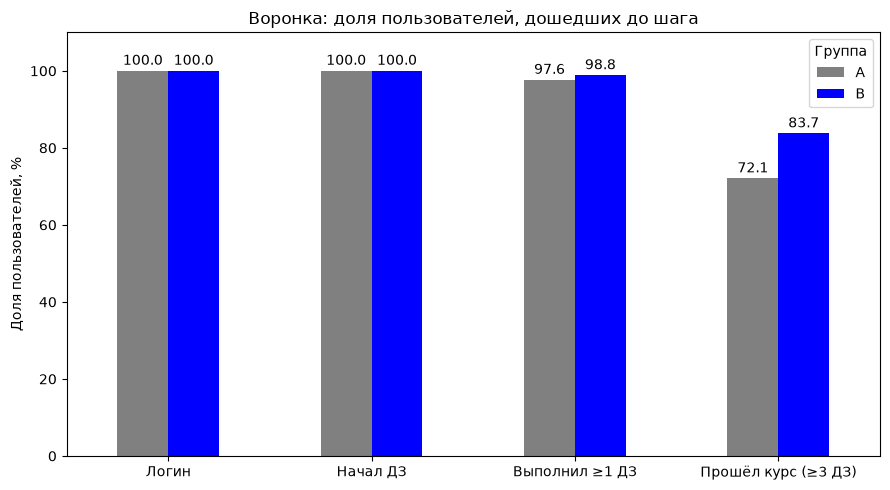

In [24]:
ax = (funnel * 100).plot(kind="bar", figsize=(9, 5), color=["gray", "blue"], rot=0)

ax.set_title("Воронка: доля пользователей, дошедших до шага")
ax.set_xlabel("")
ax.set_ylabel("Доля пользователей, %")
ax.set_xticklabels(["Логин", "Начал ДЗ", "Выполнил ≥1 ДЗ", "Прошёл курс (≥3 ДЗ)"])
ax.set_ylim(0, 110)
ax.legend(title="Группа")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=2)

plt.tight_layout()
plt.show()

### 4.2 Распределения метрик

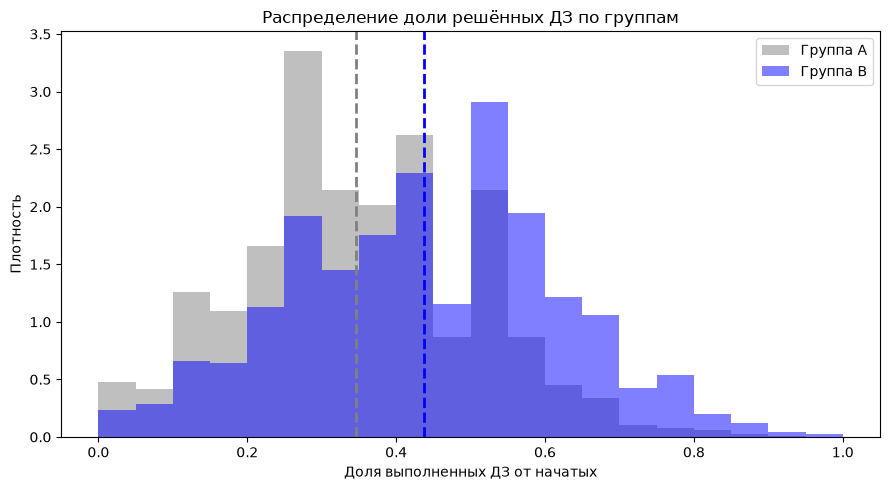

In [25]:
fig, ax = plt.subplots(figsize=(9, 5))

bins = np.linspace(0, 1, 21) 

for group, color in [("A", "gray"), ("B", "blue")]:
    data = user_metrics.loc[user_metrics["group"] == group, "solved_share"]
    ax.hist(data, bins=bins, alpha=0.5, color=color, label=f"Группа {group}", density=True)
    ax.axvline(data.mean(), color=color, linestyle="--", linewidth=2)

ax.set_title("Распределение доли решённых ДЗ по группам")
ax.set_xlabel("Доля выполненных ДЗ от начатых")
ax.set_ylabel("Плотность")
ax.legend()
plt.tight_layout()
plt.show()

In [26]:
user_metrics.groupby("group")["solved_share"].agg(["mean", "median"])

,mean,median
group,,
A,0.346066,0.333333
B,0.437967,0.444444


**Воронка.** Все пользователи в обеих группах заходили на платформу и начинали ДЗ, хотя бы одно ДЗ выполнили 97.6% в A и 98.8% в B. Основное сужение воронки – на переходе к регулярной работе (≥ 3 ДЗ): 73.8% в A против 84.7% в B. Геймификация, судя по всему, влияет не на то, начнёт ли ученик заниматься, а на то, продолжит ли он.

**Распределения.** Бинарные метрики полностью описываются долями. Доля решённых ДЗ ограничена отрезком [0, 1] и дискретна, но близка к симметричной. Среднее и медиана почти совпадают. Распределение группы B целиком сдвинуто вправо.

## 5. Выбор критерия

**Бинарные метрики** (Completion Rate, Retention D7, Retention D14) – это доли пользователей. Доля равна среднему колонки из 0 и 1, и при размере групп ~3000 человек по центральной предельной теореме её выборочное распределение близко к нормальному. Для сравнения долей используем **z-тест для пропорций**.

**Доля решённых ДЗ** – непрерывная метрика на отрезке [0, 1]. Распределение не строго нормальное, но симметричное, без тяжёлых хвостов и выбросов. При таком размере выборки ЦПТ обеспечивает нормальность выборочного среднего, поэтому используем **t-тест Уэлча**. Дополнительно проверим результат **U-критерием Манна – Уитни**.

Все тесты двусторонние, уровень значимости α = 0.05.

## 6. Статистический расчёт

### 6.1 Бинарные метрики

Сравниваем доли пользователей в группах A и B по Completion Rate, Retention D7 и Retention D14. Для каждой метрики проверяем пару гипотез из раздела «Гипотезы» двусторонним z-тестом, α = 0.05.

In [27]:
for metric in ("completion", "retention_d7", "retention_d14"):
    successes = user_metrics.groupby("group")[metric].sum()
    sizes = user_metrics.groupby("group")[metric].count()
    z_stat, p_value = proportions_ztest(successes, sizes)
    print(f"{metric}: z = {z_stat:.2f}, p-value = {p_value:.2e}")

completion: z = -10.88, p-value = 1.45e-27
retention_d7: z = -4.74, p-value = 2.13e-06
retention_d14: z = -6.14, p-value = 8.44e-10


| Метрика | z | p-value |
|---|---|---|
| Completion Rate | −10.88 | < 0.001 |
| Retention D7 | −4.74 | < 0.001 |
| Retention D14 | −6.14 | < 0.001 |

По всем трём метрикам p-value значительно меньше α = 0.05, поэтому отвергаем H0: различия между группами статистически значимы. Отрицательный знак z означает, что значение в группе A ниже, чем в B.

Поскольку мы проверяем четыре гипотезы одновременно, растёт риск хотя бы одного ложноположительного результата. С поправкой Бонферрони порог значимости составляет 0.05 / 4 = 0.0125, и все p-value остаются ниже него.

### 6.2 Доля решённых ДЗ

Сравниваем средние доли решённых ДЗ t-тестом Уэлча. Для проверки устойчивости вывода дополнительно применяем U-критерий Манна – Уитни.

In [28]:
a = user_metrics.loc[user_metrics["group"] == "A", "solved_share"]
b = user_metrics.loc[user_metrics["group"] == "B", "solved_share"]

t_stat, p_ttest = stats.ttest_ind(a, b, equal_var=False)
u_stat, p_mw = stats.mannwhitneyu(a, b, alternative="two-sided")

print(f"t-тест Уэлча: t = {t_stat:.2f}, p-value = {p_ttest:.2e}")
print(f"Манн – Уитни: p-value = {p_mw:.2e}")

t-тест Уэлча: t = -21.03, p-value = 1.01e-94
Манн – Уитни: p-value = 8.56e-90


t-тест Уэлча: t = −21.03, p-value < 0.001. Манн – Уитни: p-value < 0.001. Оба критерия дают одинаковый результат – отвергаем H0: доля решённых ДЗ в группе B статистически значимо выше.

### 6.3 Доверительные интервалы разницы
Чтобы оценить величину эффекта, строим 95%-е доверительные интервалы для разницы B − A.

In [29]:
from statsmodels.stats.proportion import confint_proportions_2indep

for metric in ("completion", "retention_d7", "retention_d14"):
    successes = user_metrics.groupby("group")[metric].sum()
    sizes = user_metrics.groupby("group")[metric].count()
    low, high = confint_proportions_2indep(
        successes["B"], sizes["B"], successes["A"], sizes["A"], compare="diff"
    )
    print(f"{metric}: разница B − A, 95% ДИ = [{low*100:.1f}; {high*100:.1f}] п.п.")

completion: разница B − A, 95% ДИ = [9.6; 13.8] п.п.
retention_d7: разница B − A, 95% ДИ = [3.1; 7.5] п.п.
retention_d14: разница B − A, 95% ДИ = [5.1; 9.8] п.п.


In [30]:
res = stats.ttest_ind(b, a, equal_var=False)
low, high = res.confidence_interval(0.95)
print(f"solved_share: разница B − A, 95% ДИ = [{low*100:.1f}; {high*100:.1f}] п.п.")

solved_share: разница B − A, 95% ДИ = [8.3; 10.0] п.п.


| Метрика | Разница B − A | 95% ДИ |
|---|---|---|
| Completion Rate | +11.7 п.п. | [9.6; 13.8] |
| Retention D7 | +5.3 п.п. | [3.1; 7.5] |
| Retention D14 | +7.4 п.п. | [5.1; 9.8] |
| Доля решённых ДЗ | +9.2 п.п. | [8.3; 10.0] |

Ни один интервал не включает ноль, все целиком лежат в положительной области. Completion Rate растёт как минимум на ~10 п.п., Retention D14 – как минимум на ~5 п.п.

### 6.4 Минимальный обнаруживаемый эффект (MDE)

MDE – наименьшая разница между группами, которую тест с данным размером выборки способен обнаружить с мощностью 80% при α = 0.05. Сравним его с наблюдаемым эффектом и оценим, достаточно ли мощным был эксперимент.

In [31]:
alpha, power = 0.05, 0.80
z_alpha = stats.norm.ppf(1 - alpha / 2) 
z_beta = stats.norm.ppf(power)           

n_a = (user_metrics["group"] == "A").sum()
n_b = (user_metrics["group"] == "B").sum()

for metric in ("completion", "retention_d7", "retention_d14"):
    p = group_means.loc["A", metric] 
    mde = (z_alpha + z_beta) * np.sqrt(p * (1 - p) * (1 / n_a + 1 / n_b))
    print(f"{metric}: MDE = {mde*100:.1f} п.п., наблюдаемый эффект = {delta[metric]*100:.1f} п.п.")

completion: MDE = 3.3 п.п., наблюдаемый эффект = 11.7 п.п.
retention_d7: MDE = 3.2 п.п., наблюдаемый эффект = 5.3 п.п.
retention_d14: MDE = 3.3 п.п., наблюдаемый эффект = 7.4 п.п.


In [32]:
sd = user_metrics.loc[user_metrics["group"] == "A", "solved_share"].std()
mde = (z_alpha + z_beta) * sd * np.sqrt(1 / n_a + 1 / n_b)
print(f"solved_share: MDE = {mde*100:.1f} п.п., наблюдаемый эффект = {delta['solved_share']*100:.1f} п.п.")

solved_share: MDE = 1.1 п.п., наблюдаемый эффект = 9.2 п.п.


| Метрика | MDE | Наблюдаемый эффект |
|---|---|---|
| Completion Rate | 3.3 п.п. | +11.7 п.п. |
| Retention D7 | 3.2 п.п. | +5.3 п.п. |
| Retention D14 | 3.3 п.п. | +7.4 п.п. |
| Доля решённых ДЗ | 1.1 п.п. | +9.2 п.п. |

Все наблюдаемые эффекты превышают MDE, значит, размера выборки было достаточно, чтобы надёжно их обнаружить.

### 6.5 Bootstrap для доли решённых ДЗ

Распределение доли решённых ДЗ не строго нормальное, поэтому дополнительно строим доверительный интервал методом bootstrap.

In [33]:
rng = np.random.default_rng(1)
n_boot = 10_000

boot_diffs = np.empty(n_boot)
for i in range(n_boot):
    sample_a = rng.choice(a.values, size=len(a), replace=True)
    sample_b = rng.choice(b.values, size=len(b), replace=True)
    boot_diffs[i] = sample_b.mean() - sample_a.mean()

low, high = np.percentile(boot_diffs, [2.5, 97.5])
print(f"Bootstrap 95% ДИ для разницы solved_share: [{low*100:.1f}; {high*100:.1f}] п.п.")


Bootstrap 95% ДИ для разницы solved_share: [8.3; 10.0] п.п.


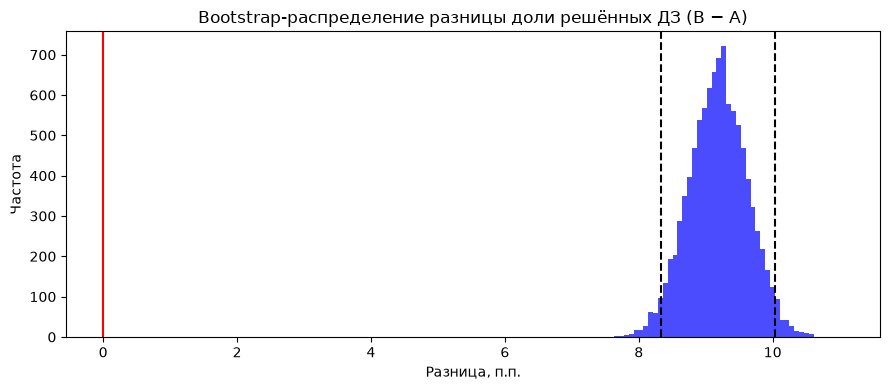

In [34]:
plt.figure(figsize=(9, 4))
plt.hist(boot_diffs * 100, bins=50, color="blue", alpha=0.7)
plt.axvline(low * 100, color="black", linestyle="--")
plt.axvline(high * 100, color="black", linestyle="--")
plt.axvline(0, color="red")
plt.title("Bootstrap-распределение разницы доли решённых ДЗ (B − A)")
plt.xlabel("Разница, п.п.")
plt.ylabel("Частота")
plt.tight_layout()
plt.show()

Bootstrap 95% ДИ: [8.3 ; 10.0] п.п. – совпадает с интервалом t-теста Уэлча. Распределение bootstrap-разниц близко к нормальному, что подтверждает применимость t-теста. Ноль в интервал не входит.

### 6.6 Проверка устойчивости

Порог «≥ 3 ДЗ» в определении Completion Rate выбран аналитически. Проверим, не зависит ли вывод от этого выбора.

In [35]:
rows = []
for n in [2, 3, 4, 5]:
    passed = (user_metrics["homework_completed"] >= n).astype(int)
    successes = passed.groupby(user_metrics["group"]).sum()
    sizes = passed.groupby(user_metrics["group"]).count()
    z_stat, p_value = proportions_ztest(successes, sizes)
    rate = successes / sizes
    rows.append({
        "порог N": n,
        "A, %": round(rate["A"] * 100, 1),
        "B, %": round(rate["B"] * 100, 1),
        "разница, п.п.": round((rate["B"] - rate["A"]) * 100, 1),
        "p-value": f"{p_value:.1e}",
    })

pd.DataFrame(rows)

,порог N,"A, %","B, %","разница, п.п.",p-value
0,2,88.8,93.2,4.5,1.5e-09
1,3,72.1,83.7,11.7,1.4e-27
2,4,49.1,71.2,22.0,1.0e-67
3,5,28.3,56.0,27.7,2.0e-104


Эффект статистически значим при любом пороге от 2 до 5 ДЗ (p < 0.001), так что вывод не зависит от выбора порога. Более того, разница между группами растёт с порогом: от +4.5 п.п. при N = 2 до +27.7 п.п. при N = 5, где доля учеников в группе B почти вдвое выше. Геймификация слабо влияет на выполнение первых заданий, но сильно – на устойчивую регулярную работу.

Все четыре метрики в группе B статистически значимо выше, чем в группе A (p < 0.001):

| Метрика | Разница B − A | 95% ДИ | MDE |
|---|---|---|---|
| Completion Rate | +11.7 п.п. | [9.6; 13.8] | 3.3 |
| Retention D7 | +5.3 п.п. | [3.1; 7.5] | 3.2 |
| Retention D14 | +7.4 п.п. | [5.1; 9.8] | 3.3 |
| Доля решённых ДЗ | +9.2 п.п. | [8.3; 10.0] | 1.1 |

Выводы устойчивы:
- для доли решённых ДЗ t-тест, Манн – Уитни и bootstrap дают согласованный результат
- эффект по Completion Rate значим при любом пороге от 2 до 5 ДЗ и растёт с ростом порога.

## 7. Интерпретация результатов

### 7.1 Сегментация по классам

In [36]:
rows = []
for metric in metrics:
    for grade in sorted(user_metrics["grade"].unique()):
        seg = user_metrics[user_metrics["grade"] == grade]
        a_seg = seg.loc[seg["group"] == "A", metric]
        b_seg = seg.loc[seg["group"] == "B", metric]

        if metric in ("completion", "retention_d7", "retention_d14"):
            _, p_value = proportions_ztest(
                [b_seg.sum(), a_seg.sum()], [len(b_seg), len(a_seg)]
            )
        else:
            _, p_value = stats.ttest_ind(b_seg, a_seg, equal_var=False)

        rows.append({
            "метрика": metric,
            "класс": grade,
            "A": round(a_seg.mean() * 100, 1),
            "B": round(b_seg.mean() * 100, 1),
            "разница, п.п.": round((b_seg.mean() - a_seg.mean()) * 100, 1),
            "p-value": round(p_value, 4),
            "значимо (α=0.007)": p_value < 0.05 / 7,
        })

segments = pd.DataFrame(rows)


segments.pivot(index="класс", columns="метрика", values="разница, п.п.")

метрика,completion,retention_d14,retention_d7,solved_share
класс,,,,
5,25.0,15.0,9.6,20.0
6,28.3,15.8,11.0,20.0
7,20.7,17.8,14.0,15.5
8,18.9,5.7,3.9,8.8
9,18.1,5.3,6.7,9.6
10,-13.1,-5.5,-1.5,-4.4
11,-16.1,-2.6,-6.8,-5.5


In [37]:
segments.pivot(index="класс", columns="метрика", values="значимо (α=0.007)")

метрика,completion,retention_d14,retention_d7,solved_share
класс,,,,
5,True,True,True,True
6,True,True,True,True
7,True,True,True,True
8,True,False,False,True
9,True,False,False,True
10,True,False,False,True
11,True,False,False,True


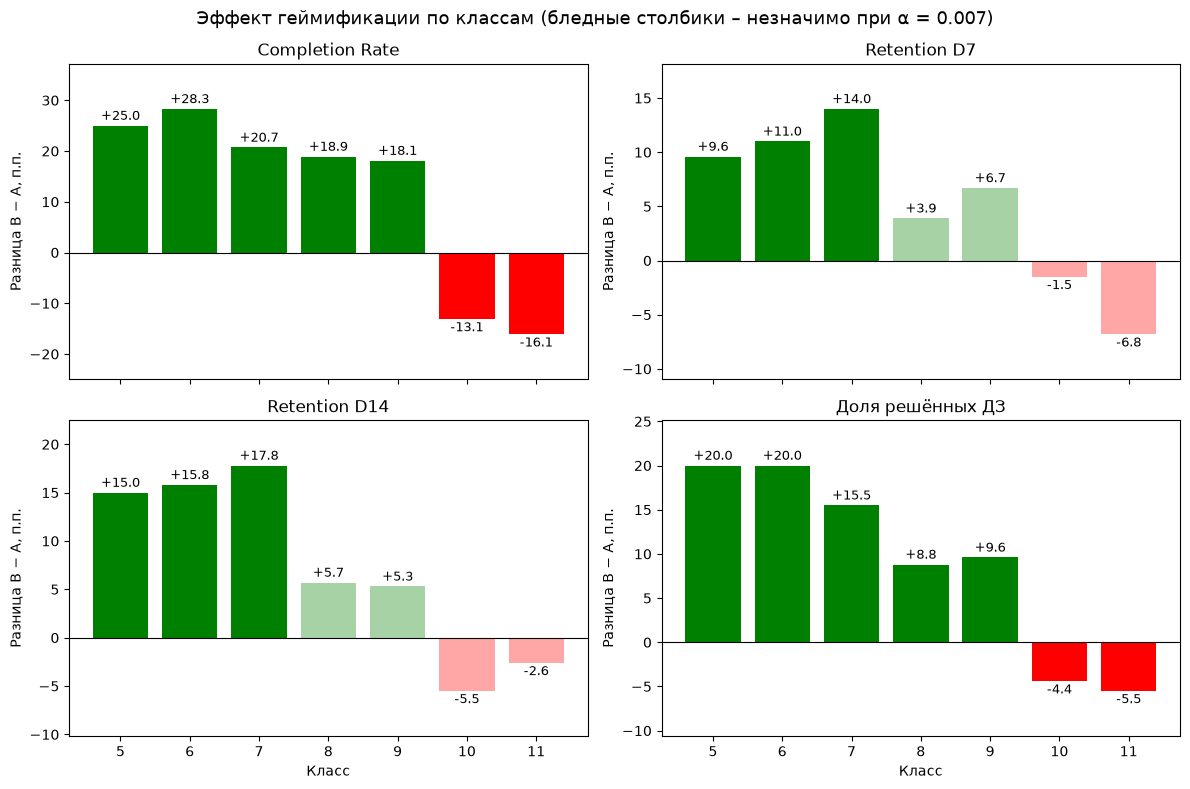

In [38]:
metric_titles = {
    "completion": "Completion Rate",
    "retention_d7": "Retention D7",
    "retention_d14": "Retention D14",
    "solved_share": "Доля решённых ДЗ",
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)

for ax, metric in zip(axes.flat, metrics):
    data = segments[segments["метрика"] == metric]
    colors = ["green" if d > 0 else "red" for d in data["разница, п.п."]]
    alphas = [1.0 if s else 0.35 for s in data["значимо (α=0.007)"]]

    bars = ax.bar(data["класс"].astype(str), data["разница, п.п."], color=colors)
    for bar, a in zip(bars, alphas):
        bar.set_alpha(a)

    ax.axhline(0, color="black", linewidth=0.8)
    ax.bar_label(bars, fmt="%+.1f", padding=2, fontsize=9)
    ax.set_title(metric_titles[metric])
    ax.set_ylabel("Разница B − A, п.п.")
    ax.margins(y=0.2)

for ax in axes[1]:
    ax.set_xlabel("Класс")

fig.suptitle("Эффект геймификации по классам (бледные столбики – незначимо при α = 0.007)", fontsize=13)
plt.tight_layout()
plt.savefig("../figures/segments_by_grade.png", dpi=150, bbox_inches="tight")
plt.show()

Эффект геймификации сильно неоднороден:
- **5–7 классы** – значимый рост по всем метрикам: Completion Rate +21…+28 п.п., Retention D14 +15…+18 п.п.
- **8–9 классы** – значимый рост Completion Rate (+18…+19 п.п.) и доли решённых ДЗ; рост Retention незначим.
- **10–11 классы** – значимое **снижение** Completion Rate (−13…−16 п.п.) и доли решённых ДЗ; снижение Retention незначимо.

Общий положительный эффект (+11.7 п.п.) складывается из сильного роста в 5–9 классах и падения в 10–11. Это неоднородный эффект воздействия. Вывод по всей выборке скрыл бы вред для старшеклассников.

### 7.2 Практическая значимость

Оценим величину эффекта для бизнеса.

- **Completion Rate: +11.7 п.п. (+16% к базовому уровню).** На каждую 1000 учеников курс регулярно проходят на ~117 человек больше; даже по нижней границе ДИ – на ~96.
- **Retention D14: +7.4 п.п. (+26%).** Через две недели на платформу возвращаются на ~74 ученика больше на каждую 1000.
- **По сегментам:** в 5–9 классах Completion Rate растёт на 18–28 п.п., то есть +180–280 учеников на 1000. В 10–11 классах фича приводит к потере ~130–160 прошедших курс учеников на каждую 1000.

Эффект практически значим: относительный рост на 16-26% – крупный результат для продуктового изменения. Без экономических и финансовых данных, - это все, что можно сказать по имеющимся данным.

Геймификация значимо улучшает метрики в целом, но эффект сильно зависит от класса: в 5–9 классах Completion Rate растёт на 18–28 п.п., а в 10–11 классах – значимо падает на 13–16 п.п. Эффект практически значим, однако раскатка на всех учеников ухудшила бы результаты старшеклассников.

## 8. Вывод

### Итоги эксперимента

В целом геймификация статистически значимо улучшает все метрики (p < 0.001):

| Метрика | A | B | Разница | 95% ДИ |
|---|---|---|---|---|
| Completion Rate | 72.1% | 83.7% | +11.7 п.п. | [9.6; 13.8] |
| Retention D7 | 72.7% | 78.0% | +5.3 п.п. | [3.1; 7.5] |
| Retention D14 | 28.8% | 36.2% | +7.4 п.п. | [5.1; 9.8] |
| Доля решённых ДЗ | 34.6% | 43.8% | +9.2 п.п. | [8.3; 10.0] |

Но эффект сильно зависит от класса:
- **5–9 классы:** Completion Rate растёт на 18–28 п.п.;
- **10–11 классы:** Completion Rate значимо **падает** на 13–16 п.п.

### Рекомендация

**Раскатить геймификацию на 5–9 классы. Для 10–11 классов – не раскатывать и отправить механику на доработку.**

Следующие шаги:
1. Включить геймификацию для учеников 5–9 классов.
2. Для 10–11 классов оставить текущий интерфейс; провести качественное исследование причин негативного эффекта и разработать версию механики, соответствующую мотивации старшеклассников, затем проверить её отдельным A/B-тестом.
3. После раскатки отслеживать метрики в течение 1–2 месяцев, чтобы исключить эффект новизны.
4. В долгосрочной перспективе – отследить, как ведут себя ученики, привыкшие к геймификации до 10 класса, после перехода в 10-й.

### Ограничения

- Completion Rate определён через порог ≥ 3 ДЗ, так как в данных нет события завершения курса; вывод устойчив к выбору порога (2–5 ДЗ).
- Нет данных финансовых и экономических данных 
- Предполагаем, что результаты не проверялись во время теста и он не был остановлен досрочно.
- Длительность теста – 3 недели – долгосрочный эффект требует наблюдений.